# Análise de despesas com viagens a serviço

Base fornecida para a atividade: viagens iniciadas entre janeiro e junho
de 2025. Algumas datas de término avançam para 2026 e são preservadas.

Fonte: [arquivo ZIP da atividade no Google Drive](https://drive.google.com/file/d/1pQjKacyHdIsyteknQbwKGM5_4hL5V4RV/view).

Execute primeiro a criação do banco, a extração Raw e a transformação
Silver. Depois, reinicie o kernel e execute todas as células em ordem.
As credenciais ficam apenas no arquivo .env local.

## Métodos e definições

- Custo da viagem: diárias + passagens + outros gastos - devolução.
  Componentes ausentes contam como zero apenas nessa soma.
- Duração: data final menos data inicial, sem adicionar um dia.
- Na pergunta 2, destino significa o texto completo do roteiro no campo
  Destinos. O custo não é repartido entre cidades.
- As perguntas 1 a 3 consultam Silver. As perguntas 4 a 7 consultam
  exclusivamente views agregadas da camada Gold.
- Cada pagamento e cada trecho contam como um registro de sua entidade;
  o custo da viagem e a soma dos pagamentos são medidas distintas.

In [1]:
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
from sqlalchemy import text

from banco import motor

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110})
engine = motor()

def consultar(sql):
    return pd.read_sql(text(sql), engine)

def numero_br(valor, casas=0):
    return f"{valor:,.{casas}f}".translate(
        str.maketrans({",": ".", ".": ","})
    )

def moeda(valor):
    return "R$ " + numero_br(valor, 2)

def mostrar_tabela(df, formatos=None, texto_longo=None):
    estilo = df.style.hide(axis="index")
    if formatos:
        estilo = estilo.format(formatos)
    if texto_longo:
        estilo = estilo.set_properties(
            subset=[texto_longo],
            **{
                "white-space": "normal",
                "overflow-wrap": "anywhere",
                "max-width": "650px",
                "text-align": "left",
            },
        )
    display(estilo)

def barras(df, categoria, medida, titulo, eixo, escala=1, casas=0):
    altura = max(4.3, 0.65 * len(df) + 1.7)
    fig, ax = plt.subplots(
        figsize=(11, altura), layout="constrained"
    )
    valores = df[medida].astype(float).to_numpy() / escala
    nomes = [
        textwrap.fill(str(nome), width=36)
        for nome in df[categoria]
    ]
    posicoes = list(range(len(df)))
    marcas = ax.barh(posicoes, valores, color="#386641")
    ax.set_yticks(posicoes, labels=nomes)
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel=eixo, ylabel="")
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda v, _: numero_br(v, casas))
    )
    ax.set_xlim(0, max(float(max(valores)), 1) * 1.3)
    ax.bar_label(
        marcas,
        labels=[numero_br(v, casas) for v in valores],
        padding=5,
    )
    ax.grid(axis="y", visible=False)
    plt.show()

print("Conexão configurada. Período da base: janeiro a junho de 2025.")

Conexão configurada. Período da base: janeiro a junho de 2025.


## Pergunta 1 - Cinco órgãos superiores com maior custo total

orgao,custo_total
Ministério da Justiça e Segurança Pública,"R$ 486.933.121,65"
Ministério da Defesa,"R$ 156.070.304,49"
Ministério da Educação,"R$ 111.291.349,34"
Ministério do Meio Ambiente e Mudança do Clima,"R$ 49.697.710,16"
Ministério da Previdência Social,"R$ 40.417.309,06"


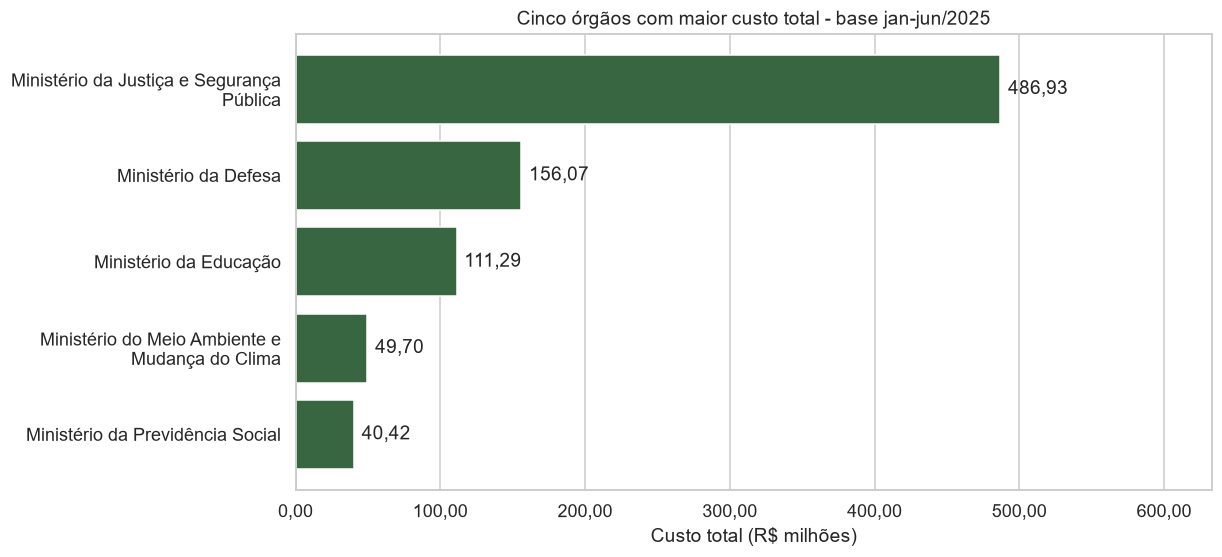

**Resultado:** Ministério da Justiça e Segurança Pública lidera o ranking, com **R$ 486.933.121,65** de custo líquido de viagens.

In [2]:
q1 = consultar('''
    SELECT
        nome_orgao_superior AS orgao,
        SUM(valor_total) AS custo_total
    FROM silver_viagem
    GROUP BY nome_orgao_superior
    ORDER BY custo_total DESC, orgao
    LIMIT 5
''')
mostrar_tabela(q1, {"custo_total": moeda})
barras(
    q1, "orgao", "custo_total",
    "Cinco órgãos com maior custo total - base jan-jun/2025",
    "Custo total (R$ milhões)", escala=1_000_000, casas=2,
)
lider = q1.iloc[0]
display(Markdown(
    f"**Resultado:** {lider['orgao']} lidera o ranking, com "
    f"**{moeda(lider['custo_total'])}** de custo líquido de viagens."
))

## Pergunta 2 - Três roteiros com maior custo médio por viagem

Roteiro 1, 2 e 3 são identificadores de apresentação. A tabela conserva
os textos completos do campo Destinos e a quantidade de viagens de cada
grupo. Uma média baseada em uma única viagem deve ser interpretada com
essa limitação.

roteiro,destino,viagens,custo_medio
Roteiro 1,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,"R$ 245.852,80"
Roteiro 2,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, São Paulo/SP, Brasília/DF, Cuiabá/MT, Brasília/DF, Teresina/PI, Brasília/DF, Maceió/AL, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Palmas/TO, Brasília/DF, Manaus/AM, Brasília/DF, Cuiabá/MT, Brasília/DF, Campinas/SP, Brasília/DF, Belo Horizonte/MG, Porto Alegre/RS, Brasília/DF, Foz do Iguaçu/PR, Brasília/DF, Fortaleza/CE, Brasília/DF, Belém/PA, Manaus/AM, Brasília/DF, Curitiba/PR, Foz do Iguaçu/PR, Brasília/DF, Fortaleza/CE, Brasília/DF, São Paulo/SP, Brasília/DF, Salvador/BA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Natal/RN, João Pessoa/PB, Brasília/DF, Brasília/DF",1,"R$ 216.729,36"
Roteiro 3,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasília/DF, Belém/PA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Belém/PA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Cuiabá/MT, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Palmas/TO, Brasília/DF, Florianópolis/SC, Brasília/DF, Belo Horizonte/MG, Brasília/DF, Belém/PA, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Belém/PA, Brasília/DF",1,"R$ 207.220,14"


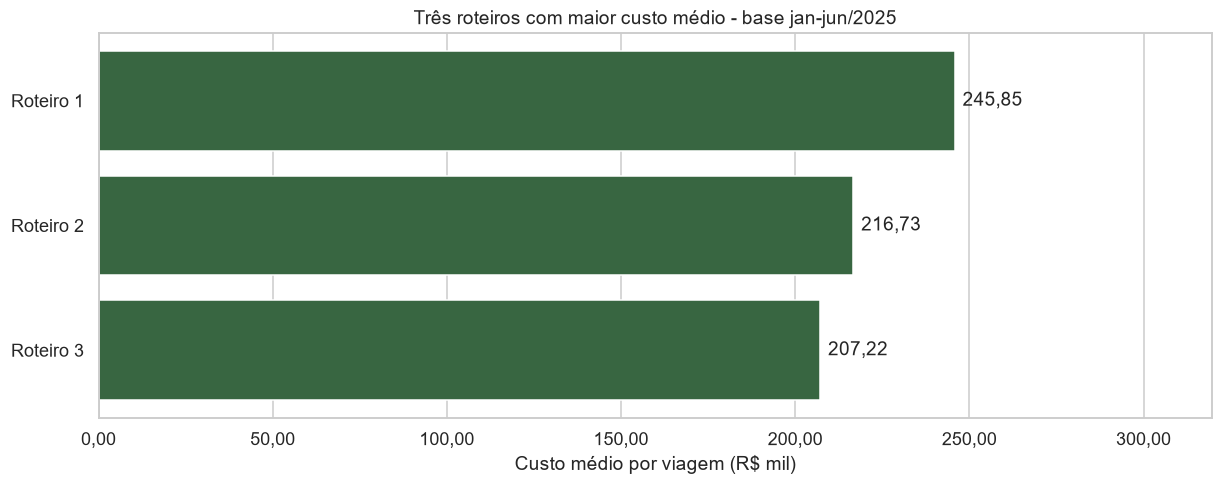

**Resultado:** Roteiro 1 apresenta a maior média: **R$ 245.852,80**, calculada sobre **1 viagem(ns)**. Os códigos do gráfico correspondem às linhas da tabela acima.

In [3]:
q2 = consultar('''
    SELECT
        destinos AS destino,
        COUNT(*) AS viagens,
        AVG(valor_total) AS custo_medio
    FROM silver_viagem
    WHERE destinos IS NOT NULL
    GROUP BY destinos
    ORDER BY custo_medio DESC, destino
    LIMIT 3
''')
q2.insert(0, "roteiro", [
    f"Roteiro {i + 1}" for i in range(len(q2))
])
mostrar_tabela(
    q2,
    {"custo_medio": moeda, "viagens": lambda v: numero_br(v)},
    texto_longo="destino",
)
barras(
    q2, "roteiro", "custo_medio",
    "Três roteiros com maior custo médio - base jan-jun/2025",
    "Custo médio por viagem (R$ mil)", escala=1_000, casas=2,
)
lider = q2.iloc[0]
display(Markdown(
    f"**Resultado:** {lider['roteiro']} apresenta a maior média: "
    f"**{moeda(lider['custo_medio'])}**, calculada sobre "
    f"**{numero_br(lider['viagens'])} viagem(ns)**. "
    "Os códigos do gráfico correspondem às linhas da tabela acima."
))

## Pergunta 3 - Viagem de maior duração e seu custo

id_viagem,nome_viajante,nome_orgao_superior,destinos,data_inicio,data_fim,duracao_dias,valor_total
0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,Mogi Mirim/SP,2025-01-13,2026-01-31,383,"R$ 0,00"


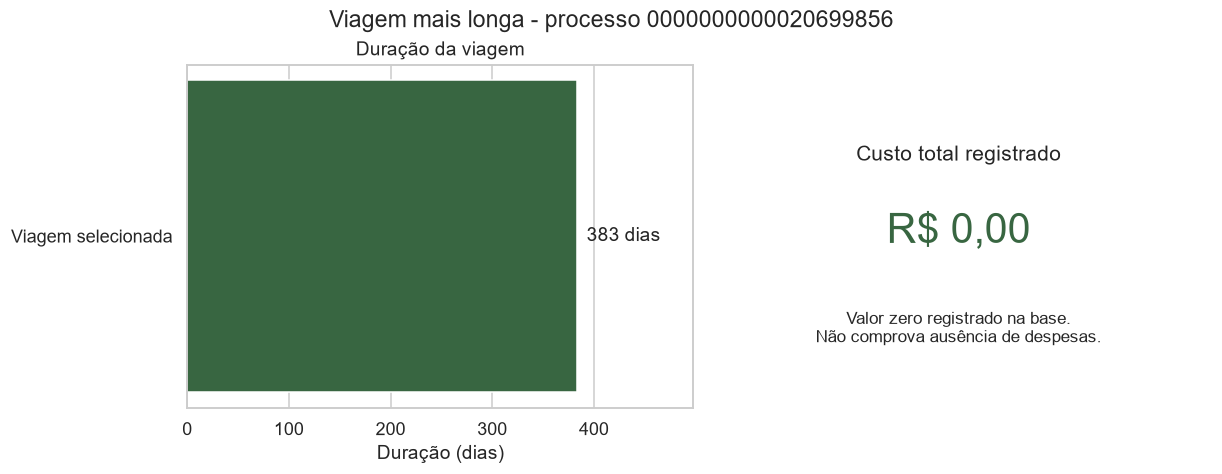

**Resultado:** processo 0000000000020699856, **383 dias** e **R$ 0,00** registrados como custo total. Duração e moeda são exibidas separadamente por terem unidades diferentes.

In [4]:
q3 = consultar('''
    SELECT
        id_viagem, nome_viajante, nome_orgao_superior, destinos,
        data_inicio, data_fim, duracao_dias, valor_total
    FROM silver_viagem
    WHERE duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC, valor_total DESC, id_viagem
    LIMIT 1
''')
mostrar_tabela(q3, {"valor_total": moeda}, texto_longo="destinos")
viagem = q3.iloc[0]
duracao = int(viagem["duracao_dias"])
custo = float(viagem["valor_total"])
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.2), layout="constrained"
)
axes[0].barh(["Viagem selecionada"], [duracao], color="#386641")
axes[0].set(
    title="Duração da viagem", xlabel="Duração (dias)",
    xlim=(0, max(duracao, 1) * 1.3),
)
axes[0].text(
    duracao, 0, f"  {numero_br(duracao)} dias", va="center"
)
axes[0].grid(axis="y", visible=False)
axes[1].axis("off")
axes[1].text(
    0.5, 0.72, "Custo total registrado",
    ha="center", transform=axes[1].transAxes, fontsize=14,
)
axes[1].text(
    0.5, 0.48, moeda(custo), ha="center",
    transform=axes[1].transAxes, fontsize=27, color="#386641",
)
nota = (
    "Valor zero registrado na base.\n"
    "Não comprova ausência de despesas."
    if custo == 0 else
    "Diárias + passagens + outros gastos - devolução."
)
axes[1].text(
    0.5, 0.23, nota, ha="center", va="center",
    transform=axes[1].transAxes, fontsize=11, wrap=True,
)
fig.suptitle(f"Viagem mais longa - processo {viagem['id_viagem']}")
plt.show()
display(Markdown(
    f"**Resultado:** processo {viagem['id_viagem']}, "
    f"**{numero_br(duracao)} dias** e **{moeda(custo)}** "
    "registrados como custo total. Duração e moeda são exibidas "
    "separadamente por terem unidades diferentes."
))

## Construção da camada Gold

A tabela gold_resumo_viagem tem uma linha por viagem. Cada tabela filha
é agregada antes dos JOINs para impedir a multiplicação de valores.

A view de resumo alimenta quatro views de métricas:
gold_pagamento_tipo_vw, gold_transporte_vw, gold_destino_uf_vw e
gold_orgao_pagador_vw. As próximas quatro perguntas consultam essas
views Gold.

Esta célula recria os objetos Gold em uma transação. Raw e Silver
permanecem como fontes de leitura.

In [5]:
gold_statements = [
    "DROP VIEW IF EXISTS gold_resumo_viagem_vw CASCADE",
    "DROP TABLE IF EXISTS gold_resumo_viagem CASCADE",
    '''
    CREATE TABLE gold_resumo_viagem AS
    WITH pagamentos AS (
        SELECT id_viagem, SUM(valor) AS valor_pago,
               COUNT(*) AS quantidade_pagamentos
        FROM silver_pagamento
        GROUP BY id_viagem
    ), passagens AS (
        SELECT id_viagem,
               SUM(
                   COALESCE(valor_passagem, 0)
                   + COALESCE(taxa_servico, 0)
               ) AS custo_passagens
        FROM silver_passagem
        GROUP BY id_viagem
    ), trechos AS (
        SELECT id_viagem, COUNT(*) AS quantidade_trechos
        FROM silver_trecho
        GROUP BY id_viagem
    )
    SELECT v.id_viagem, v.nome_orgao_superior,
           v.valor_total, v.duracao_dias,
           COALESCE(p.valor_pago, 0) AS valor_pago,
           COALESCE(p.quantidade_pagamentos, 0)
               AS quantidade_pagamentos,
           COALESCE(a.custo_passagens, 0) AS custo_passagens,
           COALESCE(t.quantidade_trechos, 0) AS quantidade_trechos
    FROM silver_viagem v
    LEFT JOIN pagamentos p USING (id_viagem)
    LEFT JOIN passagens a USING (id_viagem)
    LEFT JOIN trechos t USING (id_viagem)
    ''',
    '''
    ALTER TABLE gold_resumo_viagem
    ADD PRIMARY KEY (id_viagem)
    ''',
    '''
    CREATE VIEW gold_resumo_viagem_vw AS
    SELECT * FROM gold_resumo_viagem
    ''',
    '''
    CREATE VIEW gold_pagamento_tipo_vw AS
    SELECT p.tipo_pagamento, COUNT(*) AS pagamentos,
           SUM(p.valor) AS valor_total, AVG(p.valor) AS valor_medio
    FROM silver_pagamento p
    JOIN gold_resumo_viagem_vw g USING (id_viagem)
    WHERE p.tipo_pagamento IS NOT NULL
    GROUP BY p.tipo_pagamento
    ''',
    '''
    CREATE VIEW gold_transporte_vw AS
    SELECT t.meio_transporte, COUNT(*) AS trechos
    FROM silver_trecho t
    JOIN gold_resumo_viagem_vw g USING (id_viagem)
    WHERE t.meio_transporte IS NOT NULL
    GROUP BY t.meio_transporte
    ''',
    '''
    CREATE VIEW gold_destino_uf_vw AS
    SELECT t.destino_uf AS uf_destino, COUNT(*) AS ocorrencias
    FROM silver_trecho t
    JOIN gold_resumo_viagem_vw g USING (id_viagem)
    WHERE t.destino_uf IS NOT NULL
    GROUP BY t.destino_uf
    ''',
    '''
    CREATE VIEW gold_orgao_pagador_vw AS
    SELECT p.nome_orgao_pagador AS orgao_pagador,
           COUNT(*) AS pagamentos, SUM(p.valor) AS total_pago
    FROM silver_pagamento p
    JOIN gold_resumo_viagem_vw g USING (id_viagem)
    WHERE p.nome_orgao_pagador IS NOT NULL
    GROUP BY p.nome_orgao_pagador
    ''',
]
with engine.begin() as conn:
    for statement in gold_statements:
        conn.execute(text(statement))
print("Gold criada: tabela por viagem, view de resumo e quatro views de métricas.")

Gold criada: tabela por viagem, view de resumo e quatro views de métricas.


## Pergunta 4 - Tipo de pagamento com maior valor médio

tipo_pagamento,pagamentos,valor_medio
DIÁRIAS,401.463,"R$ 2.078,28"
PASSAGEM,188.985,"R$ 1.878,34"
Serviço correlato: seguro,4.894,"R$ 447,51"
RESTITUIÇÃO,11.574,"R$ 245,70"


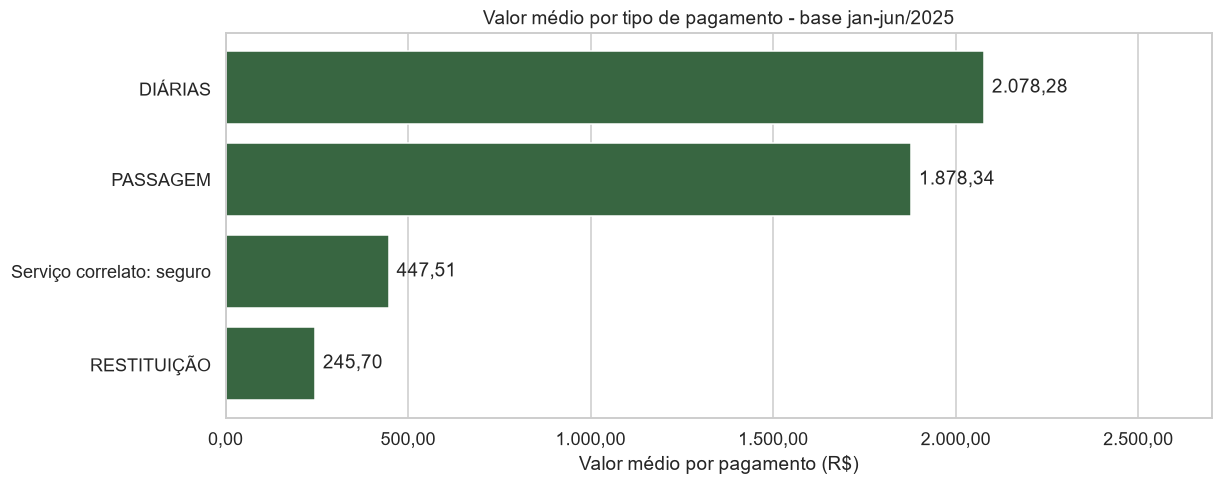

**Resultado:** DIÁRIAS possui o maior valor médio: **R$ 2.078,28** por registro de pagamento, em 401.463 registros.

In [6]:
q4 = consultar('''
    SELECT tipo_pagamento, pagamentos, valor_medio
    FROM gold_pagamento_tipo_vw
    ORDER BY valor_medio DESC, tipo_pagamento
''')
mostrar_tabela(
    q4, {"valor_medio": moeda, "pagamentos": lambda v: numero_br(v)}
)
barras(
    q4, "tipo_pagamento", "valor_medio",
    "Valor médio por tipo de pagamento - base jan-jun/2025",
    "Valor médio por pagamento (R$)", casas=2,
)
lider = q4.iloc[0]
display(Markdown(
    f"**Resultado:** {lider['tipo_pagamento']} possui o maior "
    f"valor médio: **{moeda(lider['valor_medio'])}** por registro "
    f"de pagamento, em {numero_br(lider['pagamentos'])} registros."
))

## Perguntas 5 e 6 - Transporte e UF de destino dos trechos

A primeira tabela considera os meios de transporte informados, inclusive
a categoria Inválido. A segunda considera apenas trechos com UF de
destino informada e mostra as dez UFs mais frequentes.

meio_transporte,trechos
Veículo Oficial,386.424
Aéreo,232.666
Rodoviário,64.970
Veículo Próprio,42.846
Inválido,26.659
Fluvial,8.429
Ferroviário,874
Marítimo,481


uf_destino,ocorrencias
São Paulo,82.722
Distrito Federal,79.962
Minas Gerais,50.965
Rio de Janeiro,44.197
Paraná,42.603
Pará,40.044
Rio Grande do Sul,38.684
Mato Grosso do Sul,30.516
Bahia,28.375
Pernambuco,28.372


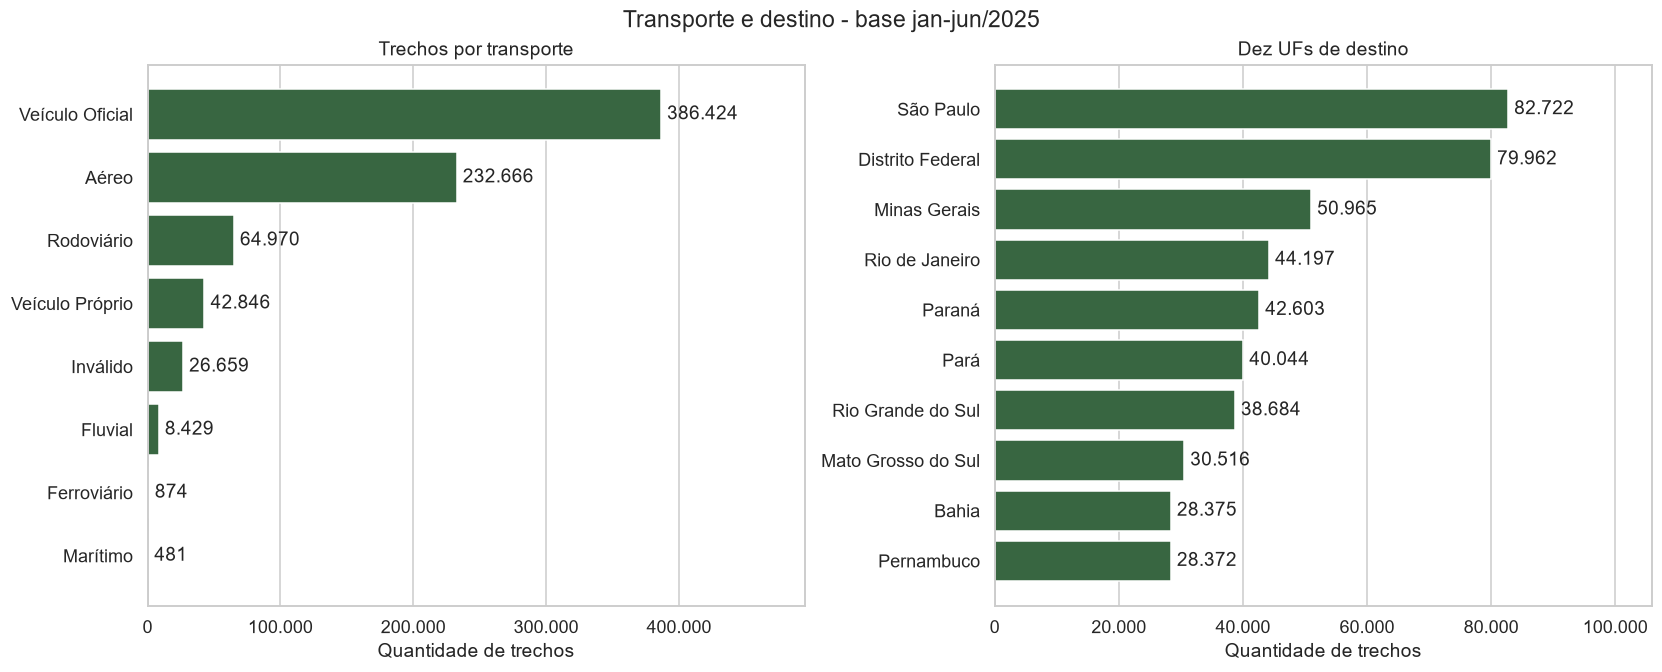

**Transporte mais frequente:** Veículo Oficial, com **386.424 trechos**.

**UF de destino mais frequente:** São Paulo, com **82.722 ocorrências**. As frequências não representam valores financeiros.

In [7]:
q5 = consultar('''
    SELECT meio_transporte, trechos
    FROM gold_transporte_vw
    ORDER BY trechos DESC, meio_transporte
''')
q6 = consultar('''
    SELECT uf_destino, ocorrencias
    FROM gold_destino_uf_vw
    ORDER BY ocorrencias DESC, uf_destino
    LIMIT 10
''')
mostrar_tabela(q5, {"trechos": lambda v: numero_br(v)})
mostrar_tabela(q6, {"ocorrencias": lambda v: numero_br(v)})
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6), layout="constrained"
)
for ax, df, categoria, medida, titulo in [
    (axes[0], q5, "meio_transporte", "trechos", "Trechos por transporte"),
    (axes[1], q6, "uf_destino", "ocorrencias", "Dez UFs de destino"),
]:
    valores = df[medida].astype(float).to_numpy()
    posicoes = list(range(len(df)))
    nomes = [
        textwrap.fill(str(nome), width=22)
        for nome in df[categoria]
    ]
    marcas = ax.barh(posicoes, valores, color="#386641")
    ax.set_yticks(posicoes, labels=nomes)
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel="Quantidade de trechos", ylabel="")
    ax.set_xlim(0, max(float(max(valores)), 1) * 1.28)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda v, _: numero_br(v))
    )
    ax.bar_label(
        marcas, labels=[numero_br(v) for v in valores], padding=4
    )
    ax.grid(axis="y", visible=False)
fig.suptitle("Transporte e destino - base jan-jun/2025")
plt.show()
display(Markdown(
    f"**Transporte mais frequente:** {q5.iloc[0]['meio_transporte']}, "
    f"com **{numero_br(q5.iloc[0]['trechos'])} trechos**.\n\n"
    f"**UF de destino mais frequente:** {q6.iloc[0]['uf_destino']}, "
    f"com **{numero_br(q6.iloc[0]['ocorrencias'])} ocorrências**. "
    "As frequências não representam valores financeiros."
))

## Pergunta 7 - Órgão pagador com maior total pago

orgao_pagador,total_pago,pagamentos
Fundo Nacional de Segurança Pública,"R$ 278.481.047,89",79.816
Sigiloso,"R$ 200.484.801,68",93.141
Comando da Aeronáutica,"R$ 81.769.144,77",46.193
Instituto Nacional do Seguro Social,"R$ 37.427.601,45",18.324
Comando do Exército,"R$ 36.872.643,95",22.837
Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com vínculo direto,"R$ 35.541.760,71",20.291
Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,"R$ 31.589.853,15",16.758
Ministério das Relações Exteriores - Unidades com vínculo direto,"R$ 25.605.376,38",3.705
Receita Federal do Brasil,"R$ 23.811.027,00",18.917
Ministério da Agricultura e Pecuária - Unidades com vínculo direto,"R$ 22.899.880,25",15.864


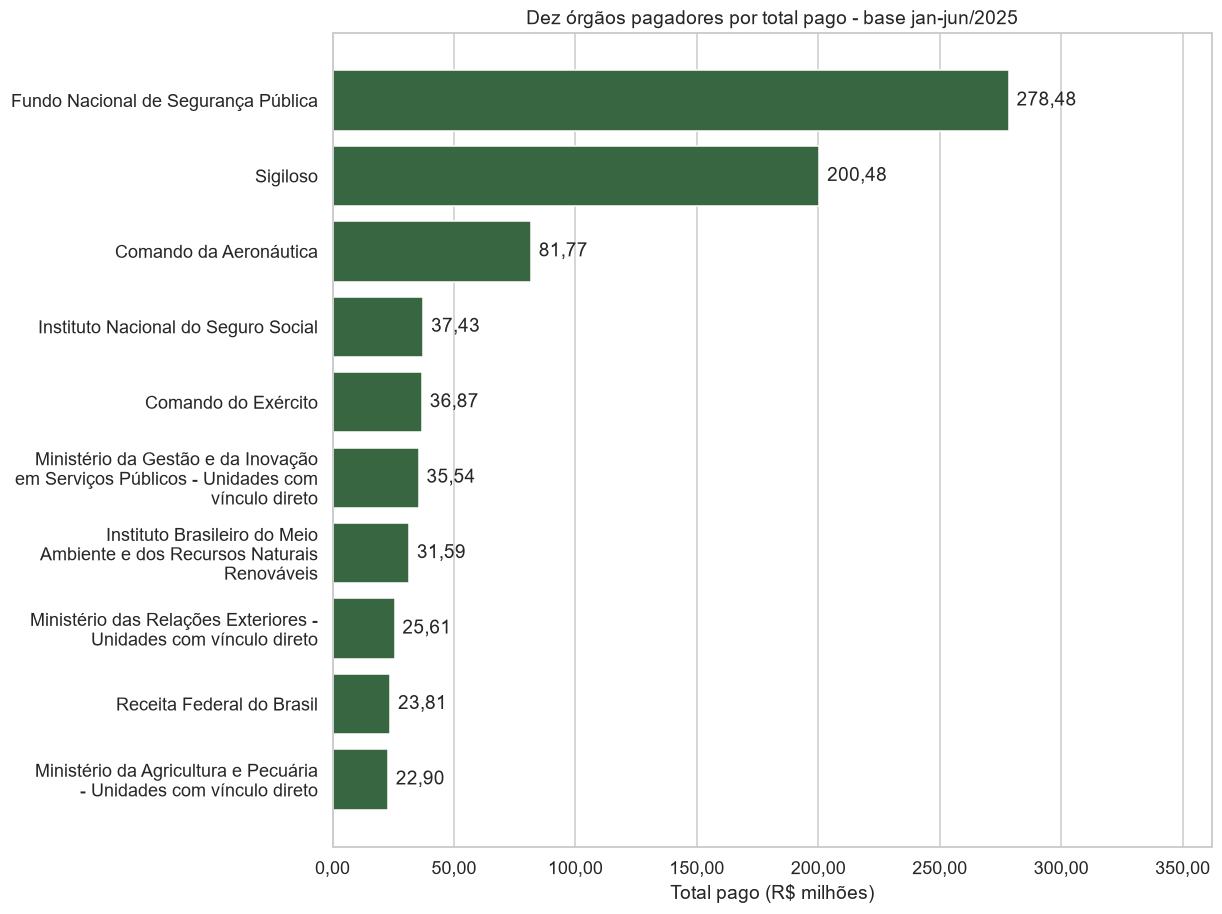

**Resultado:** Fundo Nacional de Segurança Pública apresenta o maior total pago, **R$ 278.481.047,89**, distribuído em 79.816 pagamentos. O conceito de órgão pagador difere do órgão superior de Q1.

In [8]:
q7 = consultar('''
    SELECT orgao_pagador, total_pago, pagamentos
    FROM gold_orgao_pagador_vw
    ORDER BY total_pago DESC, orgao_pagador
    LIMIT 10
''')
mostrar_tabela(
    q7, {"total_pago": moeda, "pagamentos": lambda v: numero_br(v)}
)
barras(
    q7, "orgao_pagador", "total_pago",
    "Dez órgãos pagadores por total pago - base jan-jun/2025",
    "Total pago (R$ milhões)", escala=1_000_000, casas=2,
)
lider = q7.iloc[0]
display(Markdown(
    f"**Resultado:** {lider['orgao_pagador']} apresenta o maior "
    f"total pago, **{moeda(lider['total_pago'])}**, distribuído em "
    f"{numero_br(lider['pagamentos'])} pagamentos. "
    "O conceito de órgão pagador difere do órgão superior de Q1."
))

## Conferência de contagens e reconciliação da Gold

In [9]:
entidades = ("viagem", "pagamento", "passagem", "trecho")
contagens = []
for entidade in entidades:
    linha = consultar(f'''
        SELECT
            (SELECT COUNT(*) FROM raw_{entidade}) AS raw,
            (SELECT COUNT(*) FROM silver_{entidade}) AS silver
    ''').iloc[0]
    assert int(linha["raw"]) == int(linha["silver"]), entidade
    contagens.append({
        "entidade": entidade,
        "raw": int(linha["raw"]),
        "silver": int(linha["silver"]),
    })
mostrar_tabela(pd.DataFrame(contagens))

validacoes = consultar('''
    SELECT
      (SELECT COUNT(*) FROM gold_resumo_viagem) =
      (SELECT COUNT(*) FROM silver_viagem) AS viagens,
      (SELECT COUNT(DISTINCT id_viagem) FROM gold_resumo_viagem) =
      (SELECT COUNT(*) FROM gold_resumo_viagem) AS grao_unico,
      (SELECT SUM(valor_total) FROM gold_resumo_viagem) =
      (SELECT SUM(valor_total) FROM silver_viagem) AS custo_total,
      (SELECT SUM(valor_pago) FROM gold_resumo_viagem) =
      (SELECT SUM(valor) FROM silver_pagamento) AS pagamentos,
      (SELECT SUM(quantidade_trechos) FROM gold_resumo_viagem) =
      (SELECT COUNT(*) FROM silver_trecho) AS trechos
''')
assert bool(validacoes.iloc[0].all()), "Falha de reconciliação Gold"
mostrar_tabela(validacoes)
print("Contagens conciliadas e Gold com uma linha por viagem.")

entidade,raw,silver
viagem,341860,341860
pagamento,606916,606916
passagem,167260,167260
trecho,763349,763349


viagens,grao_unico,custo_total,pagamentos,trechos
True,True,True,True,True


Contagens conciliadas e Gold com uma linha por viagem.


## Conclusões e limites

Os resultados calculados acima respondem às sete perguntas e as
verificações conciliam as contagens e os totais da Gold com Silver.
Essas verificações internas não substituem auditoria da fonte.

- A maior duração da base pode terminar em 2026. Isso não altera o
  critério de seleção pelo início no primeiro semestre de 2025.
- Um custo zero é um valor registrado na base, não prova de ausência
  de gastos. Valores não informados continuam sujeitos às limitações
  da fonte.
- As médias dos roteiros vencedores podem se basear em poucas viagens;
  a quantidade é exibida para evitar generalizações.
- Campos como cargo, CPF, UF e emissão podem estar vazios na origem.
  UFs não informadas não entram no ranking de UFs.
- Não se pode concluir causalidade ou eficiência de um órgão apenas
  pela posição nos rankings de custos, pagamentos ou frequência.